### Completion-time distribution for method A (lower bound) and method B (2 pointer)

Exact probability of each completion time, from the same recursions as the expected time (no simulation). From it we read:
- the chance of finishing within t rounds, P(T ≤ t), for each method
- probabilistic upper bounds (percentiles): "p% of runs finish within t rounds"
- the hard upper bound: the largest t with non-zero probability

Everything is random here: how many workers fail, which ones, and when.

In [1]:
import matplotlib.pyplot as plt
from pathlib import Path

from shared import (pair_schedules, A_time_distribution, B_time_distribution,
                    percentile_rounds)

Path("images").mkdir(exist_ok=True)

N = 12             # partitions
k = 6              # workers (even, for method B)
P = 0.2            # failure probability per worker per round

In [2]:
A = A_time_distribution(N, k, P)
B = B_time_distribution(pair_schedules(N, k), N, P)
t_values = list(range(1, N + 1))

def cumulative(dist):
    total, out = 0.0, []
    for t in t_values:
        total += dist.get(t, 0.0)
        out.append(total)
    return out

A_cdf, B_cdf = cumulative(A), cumulative(B)

print(f"Chance of finishing within t rounds (N={N}, k={k}, P={P})")
header = f"| {'t rounds':>8} | {'A: P(T = t)':>11} | {'B: P(T = t)':>11} | {'A: P(T <= t)':>12} | {'B: P(T <= t)':>12} |"
print(header)
print("|" + "|".join("-" * len(col) for col in header.split("|")[1:-1]) + "|")
for t, ca, cb in zip(t_values, A_cdf, B_cdf):
    print(f"| {t:>8} | {A.get(t, 0):>11.4f} | {B.get(t, 0):>11.4f} | {ca:>12.4f} | {cb:>12.4f} |")

print(f"\nExpected time: A {sum(t * p for t, p in A.items()):.4f}, B {sum(t * p for t, p in B.items()):.4f}")

Chance of finishing within t rounds (N=12, k=6, P=0.2)
| t rounds | A: P(T = t) | B: P(T = t) | A: P(T <= t) | B: P(T <= t) |
|----------|-------------|-------------|--------------|--------------|
|        1 |      0.0000 |      0.0000 |       0.0000 |       0.0000 |
|        2 |      0.0687 |      0.0687 |       0.0687 |       0.0687 |
|        3 |      0.4363 |      0.3258 |       0.5051 |       0.3946 |
|        4 |      0.2401 |      0.2956 |       0.7451 |       0.6902 |
|        5 |      0.0954 |      0.1139 |       0.8405 |       0.8040 |
|        6 |      0.0525 |      0.0718 |       0.8930 |       0.8759 |
|        7 |      0.0382 |      0.0512 |       0.9312 |       0.9270 |
|        8 |      0.0293 |      0.0335 |       0.9605 |       0.9605 |
|        9 |      0.0203 |      0.0203 |       0.9808 |       0.9808 |
|       10 |      0.0121 |      0.0121 |       0.9929 |       0.9929 |
|       11 |      0.0055 |      0.0055 |       0.9984 |       0.9984 |
|       12 |      0.00

In [3]:
# Probabilistic upper bounds: p% of runs finish within t rounds
levels = [0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
header = f"| {'Runs finishing':>14} | {'A: within':>9} | {'B: within':>9} |"
print(header)
print("|" + "|".join("-" * len(col) for col in header.split("|")[1:-1]) + "|")
for level in levels:
    print(f"| {f'{level:.0%}':>14} | {percentile_rounds(A, level):>9} | {percentile_rounds(B, level):>9} |")

| Runs finishing | A: within | B: within |
|----------------|-----------|-----------|
|            50% |         3 |         4 |
|            75% |         5 |         5 |
|            90% |         7 |         7 |
|            95% |         8 |         8 |
|            99% |        10 |        10 |
|           100% |        12 |        12 |


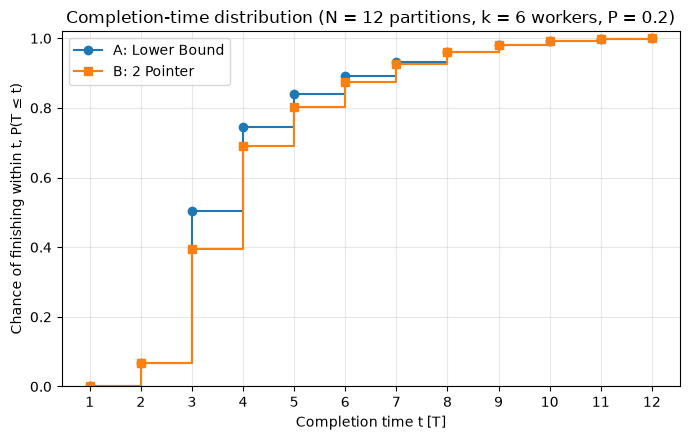

In [4]:
plt.figure(figsize=(7, 4.5))
plt.step(t_values, A_cdf, where="post", marker="o", label="A: Lower Bound")
plt.step(t_values, B_cdf, where="post", marker="s", label="B: 2 Pointer")
plt.xticks(t_values)
plt.ylim(0, 1.02)
plt.xlabel("Completion time t [T]")
plt.ylabel("Chance of finishing within t, P(T ≤ t)")
plt.title(f"Completion-time distribution (N = {N} partitions, k = {k} workers, P = {P})")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(Path("images") / "e_completion_time_distribution.png", dpi=150)
plt.show()